1. How many rows and columns are in the dataset?

2. Are there any duplicate passenger records?

3. Which columns contain missing values, and how many are missing in each?

4. What percentage of values are missing in each column?

5. Are there any incorrect data types or inconsistent category labels?

6. Are there any suspicious outliers in age or fare?

7. How should missing age, embarkation, and deck values be handled?

8. Are any columns redundant or duplicates of information in other columns?





In [367]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [368]:
df = pd.read_csv('titanic.csv')


1. How many rows and columns are in the dataset?


In [369]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)


Number of rows: 891
Number of columns: 15
Dataset shape: (891, 15)


According to the above dataset there are 891 rows and 15 columns.

2. Are there any duplicate passenger records?


In [370]:

# Check duplicate records
duplicates = df.duplicated().sum()

print("Total duplicate rows:", duplicates)

# Display duplicate records
duplicate_records = df[df.duplicated()]

print(duplicate_records)


Total duplicate rows: 107
     survived  pclass     sex   age  sibsp  parch     fare embarked   class  \
47          1       3  female   NaN      0      0   7.7500        Q   Third   
76          0       3    male   NaN      0      0   7.8958        S   Third   
77          0       3    male   NaN      0      0   8.0500        S   Third   
87          0       3    male   NaN      0      0   8.0500        S   Third   
95          0       3    male   NaN      0      0   8.0500        S   Third   
..        ...     ...     ...   ...    ...    ...      ...      ...     ...   
870         0       3    male  26.0      0      0   7.8958        S   Third   
877         0       3    male  19.0      0      0   7.8958        S   Third   
878         0       3    male   NaN      0      0   7.8958        S   Third   
884         0       3    male  25.0      0      0   7.0500        S   Third   
886         0       2    male  27.0      0      0  13.0000        S  Second   

       who  adult_male de

Titanic dataset does not contain unique passenger identifiers or passenger names that would allow us to verify duplicate passenger identity.

3. Which columns contain missing values, and how many are missing in each?


In [371]:
# count missing values in each columns
missing_value = df.isnull().sum()

# Display only missing values
print(missing_value[missing_value>0])



age            177
embarked         2
deck           688
embark_town      2
dtype: int64


Age , embarked, deck and embark_town are column names containing the null value of 177 , 2, 688, and 2 respectively.

4. What percentage of values are missing in each column?

In [372]:
# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display results
print(missing_percentage[missing_percentage > 0].round(2))

age            19.87
embarked        0.22
deck           77.22
embark_town     0.22
dtype: float64


5. Are there any incorrect data types or inconsistent category labels?

In [373]:
# Check data types
print(df.dtypes)

survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
deck               str
embark_town        str
alive              str
alone             bool
dtype: object


The data types are generally appropriate.

6. Are there any suspicious outliers in age or fare?

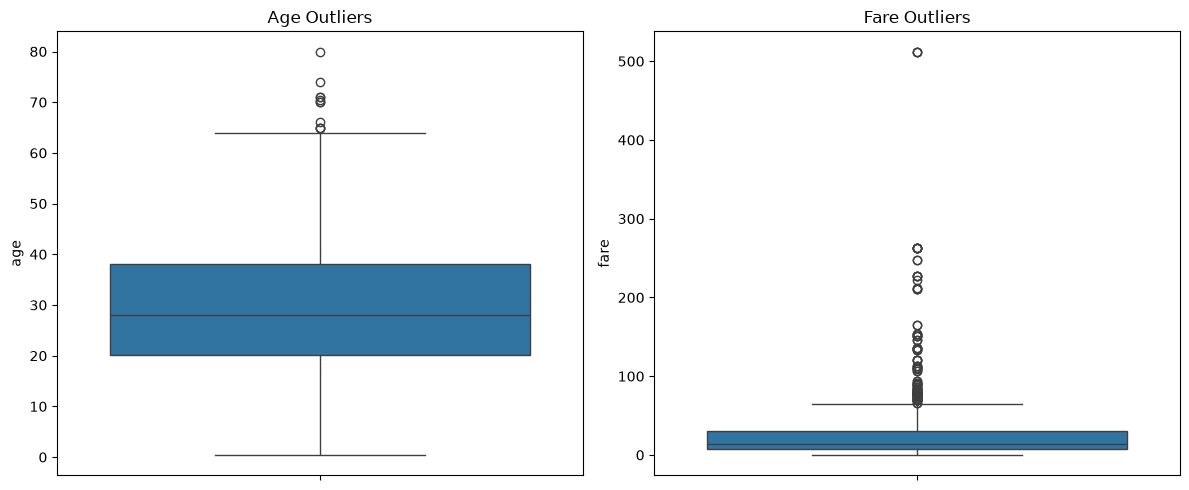

In [374]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df["age"])
plt.title("Age Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(y=df["fare"])
plt.title("Fare Outliers")

plt.tight_layout()
plt.show()

high fares may be legitimate because passengers travelled in different classes and accommodation arrangements.

7. How should missing age, embarkation, and deck values be handled?

We need to handle missing values based on the type of data and the percentage of missing values.

In [375]:
# Replace missing age with median
df["age"] = df["age"].fillna(df["age"].median())

print("Missing age values:", df["age"].isnull().sum())

Missing age values: 0


In [376]:
# Replace missing embarked values with mode
df["embarked"] = df["embarked"].fillna(
    df["embarked"].mode()[0]
)

print("Missing embarked values:", df["embarked"].isnull().sum())

Missing embarked values: 0


In [377]:
embark_mapping = {
    "S": "Southampton",
    "C": "Cherbourg",
    "Q": "Queenstown"
}

df["embark_town"] = df["embark_town"].fillna(
    df["embarked"].map(embark_mapping)
)

print("Missing embark_town values:",
      df["embark_town"].isnull().sum())

Missing embark_town values: 0


Since more than 77% of the values are missing in deck columns, replacing them with the mode could introduce misleading information.

so i will keep the missing value as unknown

In [378]:
df["deck"] = df["deck"].fillna("Unknown")
print(f'deck missing value ',df['deck'].isnull().sum())

deck missing value  0


In [379]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64

8. Are any columns redundant or duplicates of information in other columns?

Yes. Some columns provide the same information or information that can be derived from other columns.

Column 1	             Column 2                Relationship

survived	 ----- -----           alive	        -----        Same survival information

pclass   	 -----            class	        -----        Same passenger class

embarked	   -----          embark_town	 -----               Same embarkation location

sex + age category	 -----        who	     -----           Related passenger classification

sex + who	       -----      adult_male	     -----           Adult male indicator

sibsp + parch	   -----          alone	      -----          Family travelling indicator

Explanation of important relationships:

survived and alive
- survived = 1 means alive.
- survived = 0 means not alive.
- alive contains the same information in text format.

pclass and class
- pclass = 1 means First class.
- pclass = 2 means Second class.
- pclass = 3 means Third class.

embarked and embark_town
- S = Southampton.
- C = Cherbourg.
- Q = Queenstown.

alone
- This indicates whether a passenger travelled without family members.
- It can be derived from sibsp and parch.

removing redundant columns to avoid duplicate information



In [380]:
df.drop(columns=["alive", "class", "embarked"],inplace=True)


Saving titanic cleaned data into new csv file

In [381]:
df.to_csv('titanic_cleaned.csv', index=False)

What percentage of male and female passengers survived?


In [382]:
df[df['survived'] == 1]['sex'].value_counts()

sex
female    233
male      109
Name: count, dtype: int64

In [383]:
# percentage of male and female survived are given below

df.groupby('sex')['survived'].mean() * 100

sex
female    74.203822
male      18.890815
Name: survived, dtype: float64

Which passenger class had the highest survival rate?


pclass
1    62.962963
2    47.282609
3    24.236253
Name: survived, dtype: float64


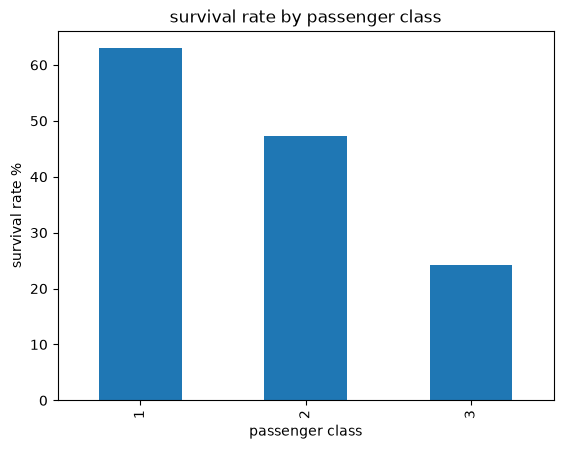

In [384]:
class_survival_rate = df.groupby('pclass')['survived'].mean()*100
print(class_survival_rate)

class_survival_rate.plot(kind='bar')
plt.title('survival rate by passenger class')
plt.ylabel('survival rate %')
plt.xlabel('passenger class')
plt.show()


pclass and class
- pclass = 1 means First class.
- pclass = 2 means Second class.
- pclass = 3 means Third class.
> according to the dataset First class passenger had the highest survival rate

Which embarkation town had the highest survival rate?


embark_town
Cherbourg      55.357143
Queenstown     38.961039
Southampton    33.900929
Name: survived, dtype: float64


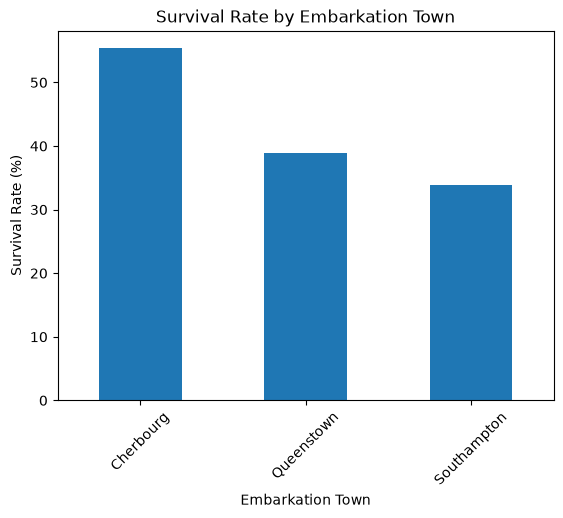

In [385]:
# Calculate survival percentage by embarkation town
survival_rate = df.groupby('embark_town')['survived'].mean() * 100
print(survival_rate)

survival_rate.plot(kind='bar')

plt.title('Survival Rate by Embarkation Town')
plt.xlabel('Embarkation Town')
plt.ylabel('Survival Rate (%)')
plt.xticks(rotation=45)
plt.show()

Did passengers who paid higher fares have better survival chances?


survived
0    2211.788689
1    4839.540760
Name: fare, dtype: float64


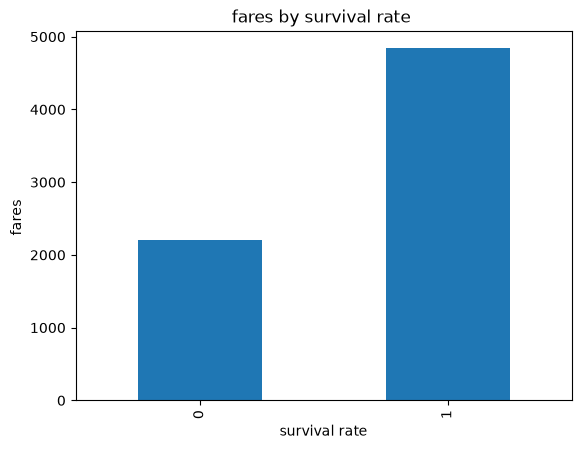

In [386]:
fares_survival_rate = df.groupby('survived')['fare'].mean()*100
print(fares_survival_rate)

fares_survival_rate.plot(kind='bar')
plt.title('fares by survival rate ')
plt.ylabel('fares ')
plt.xlabel('survival rate')

plt.show()

Yes, According to the above bar graph those passenger who paid higher fares have better survival chances.

Did travelling alone affect survival?


alone
False    50.564972
True     30.353818
Name: survived, dtype: float64


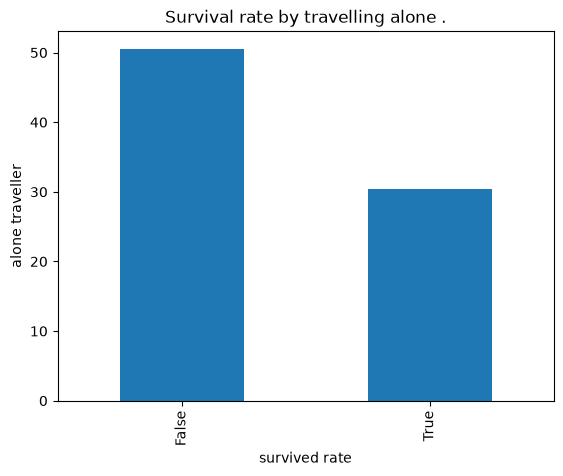

In [387]:
travel_alone_survival= df.groupby('alone')['survived'].mean()*100
print(travel_alone_survival)

travel_alone_survival.plot( kind='bar')
plt.title('Survival rate by travelling alone .')
plt.ylabel('alone traveller')
plt.xlabel('survived rate')
plt.show()

Which age group had the highest survival rate?

In [388]:
df['age'].value_counts()

age
28.00    202
24.00     30
22.00     27
18.00     26
19.00     25
        ... 
24.50      1
0.67       1
0.42       1
34.50      1
74.00      1
Name: count, Length: 88, dtype: int64

Age group of 28 years old had the highest survival rate